# Reading and preprocessing a GPR profile

This notebook loads one simulated B-scan and defines each processing step inline. Each image is the electric field Ez. Time increases downward.

The record is a gprMax model of a metal pipe in a dielectric half-space: a 1.5 GHz Ricker, soil permittivity 6, conductivity 0, and a pipe whose centre is 5 cm below the surface at x = 0.12 m. The file is `data/sim/pipe_study/f1.5_e6_s0_d5/pipe_merged.h5`.

Open it from the repository root in the `gprMax-v4` environment.

## Setup

Paths, the scan file, and the windows used below. Each processing step is defined in its own section.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

def repo_root():
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "data" / "sim" / "pipe_study").is_dir():
            return candidate
    raise FileNotFoundError("open this notebook from the GPRadar repository")

ROOT = repo_root()

%matplotlib inline

SCAN = ROOT / "data" / "sim" / "pipe_study" / "f1.5_e6_s0_d5" / "pipe_merged.h5"
# First break at 5% of the peak. Both windows are longer than one cycle of
# the 1.5 GHz pulse and much shorter than the 5 ns record.
THRESHOLD = 0.05
DEWOW_WINDOW_NS = 2.0
AGC_WINDOW_NS = 2.0

def _samples(data):
    """Float copy of a (samples, traces) array. The original is left alone."""
    values = np.array(data, dtype=np.float64, copy=True)
    if values.ndim != 2 or values.shape[0] == 0 or values.shape[1] == 0:
        raise ValueError("data must have shape (samples, traces)")
    return values


def _like(data, values):
    return np.asarray(values, dtype=np.asarray(data).dtype)


## Reading the file

The merged file is HDF5. `rxs/rx1/Ez` is the electric field, one column per trace and one row per time sample. The root attribute `dt` is the sample interval in seconds. Receiver coordinates under `trace_metadata` set the horizontal axis. gprMax drops the source waveform when it merges traces, so this file has no centre frequency. That number is in `data/sim/pipe_study/cases.csv`.


In [2]:
import csv

import h5py

COMPONENT = "Ez"
RECEIVER = "rx1"

with h5py.File(SCAN, "r") as output:
    dt = float(output.attrs["dt"])
    data = np.asarray(output["rxs"][RECEIVER][COMPONENT], dtype=float)
    if data.ndim == 1:
        data = data[:, np.newaxis]

    recorded = output.get(f"trace_metadata/rxs/{RECEIVER}/Position")
    if recorded is not None and recorded.shape == (data.shape[1], 3):
        positions = np.asarray(recorded, dtype=float)
    else:
        origin = np.asarray(output["rxs"][RECEIVER].attrs["Position"], dtype=float)
        cell = np.asarray(output.attrs["dx_dy_dz"], dtype=float)
        step = np.asarray(output.attrs["rxsteps"], dtype=float)
        positions = origin + np.arange(data.shape[1])[:, np.newaxis] * (cell * step)

    excitation = output.get("srcs/src1/excitation")
    frequency = None
    if excitation is not None and "WaveformFrequency" in excitation.attrs:
        frequency = float(excitation.attrs["WaveformFrequency"])

distances = np.linalg.norm(np.diff(positions, axis=0), axis=1)
trace_spacing = float(np.median(distances))

with (SCAN.parent.parent / "cases.csv").open(newline="") as handle:
    case = next(row for row in csv.DictReader(handle) if row["tag"] == SCAN.parent.name)
center_hz = float(case["freq_hz"])

print(f"shape (samples, traces): {data.shape}")
print(f"dt: {dt * 1e12:.3f} ps")
print(f"trace spacing: {trace_spacing * 1e3:.1f} mm")
print(f"component: {COMPONENT}")
print(f"frequency stored in the HDF5 file: {frequency}")
print(
    f"case: {center_hz / 1e9:.1f} GHz, εr = {case['eps_r']}, "
    f"σ = {case['sigma_s_m']} S/m, depth = {float(case['depth_m']) * 100:.0f} cm, "
    f"target x = {case['target_x_m']} m"
)

time_ns = np.arange(data.shape[0]) * dt * 1e9
position = positions[:, 0]
extent = [position[0], position[-1], time_ns[-1], time_ns[0]]


shape (samples, traces): (1061, 60)
dt: 4.717 ps
trace spacing: 2.0 mm
component: Ez
frequency stored in the HDF5 file: None
case: 1.5 GHz, εr = 6.0, σ = 0.0 S/m, depth = 5 cm, target x = 0.120 m


## How the images are drawn

The colour scale of each panel is symmetric about zero and stops at the 99th percentile of that panel's absolute amplitude. Red is positive Ez and blue is negative. Because each step has its own scale, a change in the colour bar means the amplitudes changed. It does not mean the wavelet flipped sign.

In [3]:
def show_scan(data, title):
    limit = float(np.percentile(np.abs(data), 99))
    if limit == 0:
        limit = 1.0
    fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
    image = ax.imshow(
        data,
        extent=extent,
        aspect="auto",
        cmap="seismic",
        vmin=-limit,
        vmax=limit,
        interpolation="nearest",
    )
    fig.colorbar(image, ax=ax, label="Ez")
    ax.set_title(title)
    ax.set_xlabel("Trace position [m]")
    ax.set_ylabel("Two-way time [ns]")
    plt.show()

## Raw record

The strong horizontal band near 1 ns is the direct arrival between the transmitter and the receiver. The curve under it is the reflection from the pipe.

The antenna does not only look straight down. It still sees the pipe before and after it passes overhead, so the path is shortest at the apex and longer on either side. That curve is a hyperbola. The vertical axis is two-way travel time, not depth: depth is `d = v t / 2`, with `v = c / √εr`. For εr = 6 the wave in the soil travels at about 0.12 m/ns, so a centre at 5 cm returns a little after the direct wave.

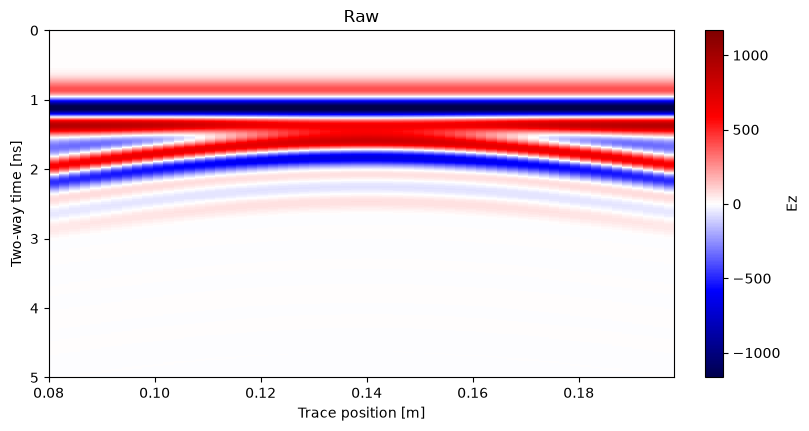

In [4]:
raw = data
show_scan(raw, "Raw")

## Time zero

The direct wave is the time reference for the record. `time_zero` finds, on each trace, the first sample whose absolute amplitude reaches 5% of that trace's peak, and shifts that sample to the start. Samples left empty at the end are set to zero.

After the shift, two-way time is measured from a common origin, so a later reflection lines up from trace to trace. On this file the pick is the same on every trace, because the direct wave is horizontal, and it sits a fraction of a nanosecond down the record. The section moves up by that amount. On a field record the air wave can sit much further down the window, and the same step is what makes the traces comparable.

first-break picks: 136 to 136 samples


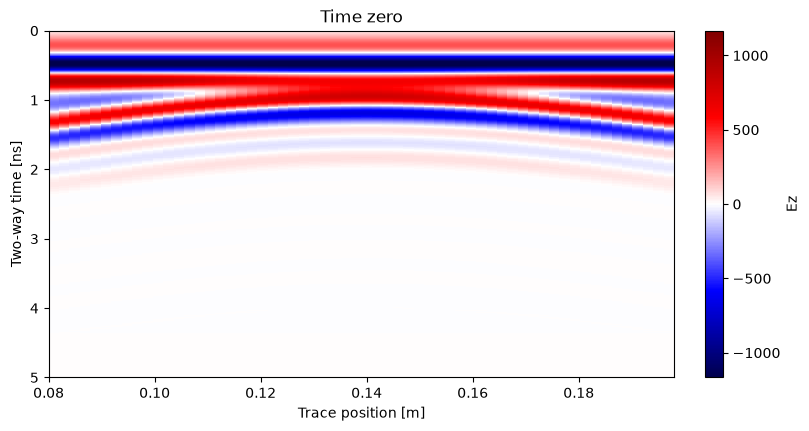

In [5]:
def time_zero(data, dt, method="threshold", threshold=0.05):
    """Move each trace up so the first break is at the start of the record."""
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("dt must be a positive sample interval in seconds")
    if method != "threshold":
        raise ValueError("method must be 'threshold'")
    if not np.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError("threshold must be between 0 and 1")

    values = _samples(data)
    magnitude = np.abs(values)
    n_samples, n_traces = values.shape
    picks = np.empty(n_traces, dtype=int)
    shifted = np.zeros_like(values)
    for index in range(n_traces):
        trace = magnitude[:, index]
        level = float(threshold) * float(trace.max())
        above = np.flatnonzero(trace >= level)
        pick = int(above[0]) if above.size else 0
        picks[index] = pick
        shifted[: n_samples - pick, index] = values[pick:, index]
    return _like(data, shifted), picks


zeroed, picks = time_zero(raw, dt, method="threshold", threshold=THRESHOLD)
print(f"first-break picks: {picks.min()} to {picks.max()} samples")
show_scan(zeroed, "Time zero")

## Dewow

Coupling between the antennas, and induction in the ground, add a slowly varying bias called wow. It sits well below the antenna frequency and tilts the baseline of a trace.

`dewow` subtracts a running mean along time. The window is 2 ns: longer than one cycle of the 1.5 GHz pulse (about 0.7 ns) and much shorter than the 5 ns record, so the reflection stays and the bias goes.

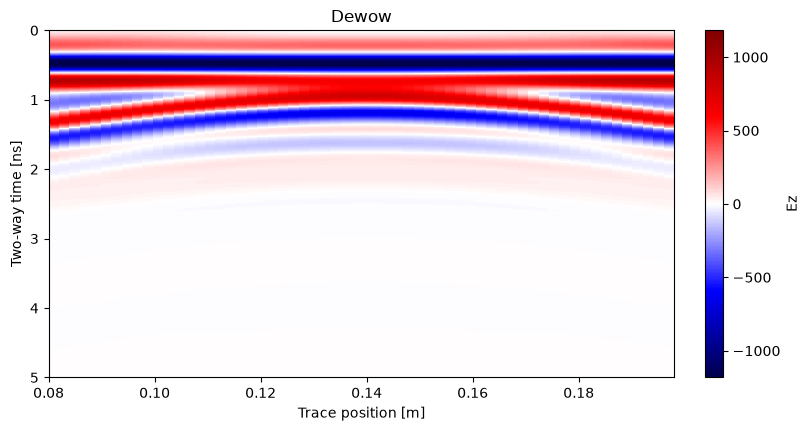

In [6]:
from scipy.ndimage import uniform_filter1d


def dewow(data, dt, window_ns):
    """Subtract a running mean along time and remove the low-frequency wow."""
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("dt must be a positive sample interval in seconds")
    if not np.isfinite(window_ns) or window_ns <= 0:
        raise ValueError("window_ns must be positive")
    values = _samples(data)
    window = max(int(round(window_ns * 1e-9 / dt)), 1)
    trend = uniform_filter1d(values, size=window, axis=0, mode="nearest")
    return _like(data, values - trend)


dewowed = dewow(zeroed, dt, DEWOW_WINDOW_NS)
show_scan(dewowed, "Dewow")

## Background removal

The direct wave and any system ringing arrive at nearly the same time on every trace, so they draw a horizontal band. `remove_background` subtracts the mean trace. A pipe changes from trace to trace, so its hyperbola remains.

On this 12 cm profile the hyperbola covers most of the traces, so part of the target is inside the mean. Subtracting it leaves artefacts near the apex: a horizontal remnant where the top of the curve used to be. A longer profile, or subtracting a simulation that has no target, avoids that.

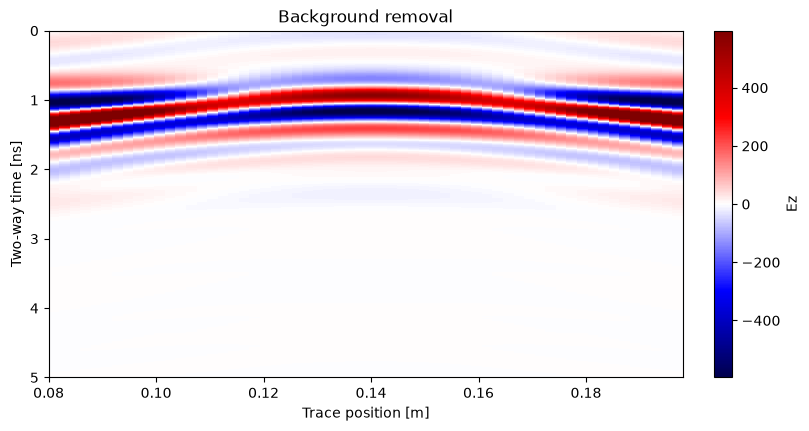

In [7]:
def remove_background(data):
    """Subtract the mean trace and remove the horizontal direct wave."""
    values = _samples(data)
    background = values.mean(axis=1, keepdims=True)
    return _like(data, values - background)


cleaned = remove_background(dewowed)
show_scan(cleaned, "Background removal")

## Band-pass

The pulse is concentrated around the antenna frequency. `default_band` keeps half to twice that frequency. For 1.5 GHz the pass band is 0.75–3 GHz. Energy below the band is leftover wow and drift. Energy above it is noise.

`bandpass` is a zero-phase Butterworth. The same filter runs forwards and then backwards, so the reflection is not shifted in time. The plot under the section is the mean single-sided amplitude spectrum of the traces. The shaded region is the pass band. The peak near 2 GHz stays, and the tails outside the band drop.

pass band: 0.75–3.00 GHz


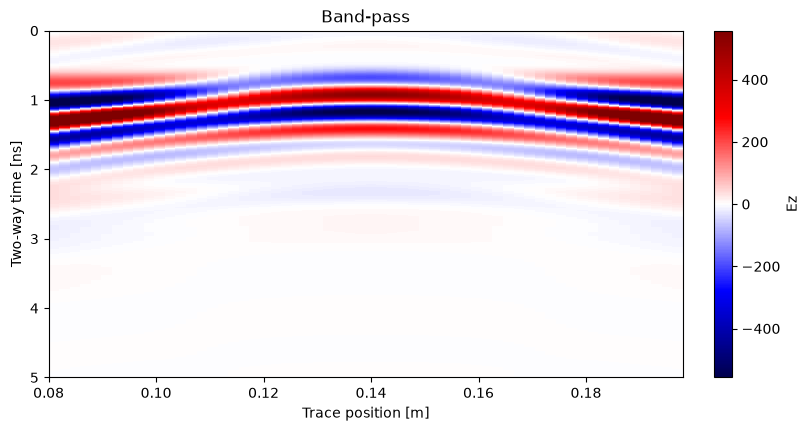

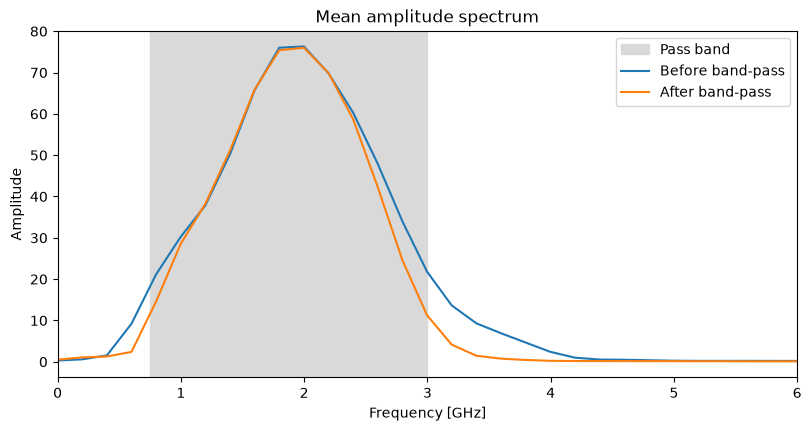

In [8]:
from scipy.signal import butter, sosfiltfilt


def default_band(center_hz, nyquist_hz):
    """Pass band from half to twice the centre frequency, kept below Nyquist."""
    if not np.isfinite(center_hz) or center_hz <= 0:
        raise ValueError("center_hz must be positive")
    if not np.isfinite(nyquist_hz) or nyquist_hz <= 0:
        raise ValueError("nyquist_hz must be positive")
    low = 0.5 * float(center_hz)
    high = min(2.0 * float(center_hz), float(nyquist_hz) * (1.0 - 1e-6))
    if not 0 < low < high < nyquist_hz:
        raise ValueError("centre frequency does not leave a band below Nyquist")
    return low, high


def bandpass(data, dt, low_hz, high_hz, order=4):
    """Zero-phase Butterworth band-pass along time. The pulse is not shifted."""
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("dt must be a positive sample interval in seconds")
    nyquist = 0.5 / float(dt)
    if int(order) != order or order < 1:
        raise ValueError("order must be a positive integer")
    if not (np.isfinite(low_hz) and np.isfinite(high_hz) and 0 < low_hz < high_hz < nyquist):
        raise ValueError("require 0 < low_hz < high_hz < Nyquist")
    values = _samples(data)
    sos = butter(int(order), [low_hz, high_hz], btype="bandpass", fs=1.0 / float(dt), output="sos")
    return _like(data, sosfiltfilt(sos, values, axis=0))


def amplitude_spectrum(data, dt):
    """Mean single-sided amplitude spectrum across the traces."""
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("dt must be a positive sample interval in seconds")
    values = _samples(data)
    n_samples = values.shape[0]
    spectrum = np.abs(np.fft.rfft(values, axis=0))
    spectrum *= 2.0 / n_samples
    spectrum[0] /= 2.0
    if n_samples % 2 == 0:
        spectrum[-1] /= 2.0
    frequencies = np.fft.rfftfreq(n_samples, d=float(dt))
    return frequencies, spectrum.mean(axis=1)


low_hz, high_hz = default_band(center_hz, nyquist_hz=0.5 / dt)
filtered = bandpass(cleaned, dt, low_hz, high_hz)
print(f"pass band: {low_hz / 1e9:.2f}–{high_hz / 1e9:.2f} GHz")
show_scan(filtered, "Band-pass")

frequency_before, amplitude_before = amplitude_spectrum(cleaned, dt)
frequency_after, amplitude_after = amplitude_spectrum(filtered, dt)
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
ax.axvspan(low_hz / 1e9, high_hz / 1e9, color="0.85", label="Pass band")
ax.plot(frequency_before / 1e9, amplitude_before, label="Before band-pass")
ax.plot(frequency_after / 1e9, amplitude_after, label="After band-pass")
ax.set_xlim(0, 6)
ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Amplitude")
ax.set_title("Mean amplitude spectrum")
ax.legend()
plt.show()

## Gain

Geometric spreading and attenuation make a late reflection weaker than an early one, even when the target is the same. `gain_agc` divides each sample by the root-mean-square amplitude inside a 2 ns window, so the envelope along a trace is roughly flat and a weaker arrival stays visible.

The window is about the length of the wavelet rather than a single half-cycle. A constant of `1e-8` is added to the RMS so a quiet sample is not divided by zero. That also lifts the ringing at the end of the record, where there is no target left to see.

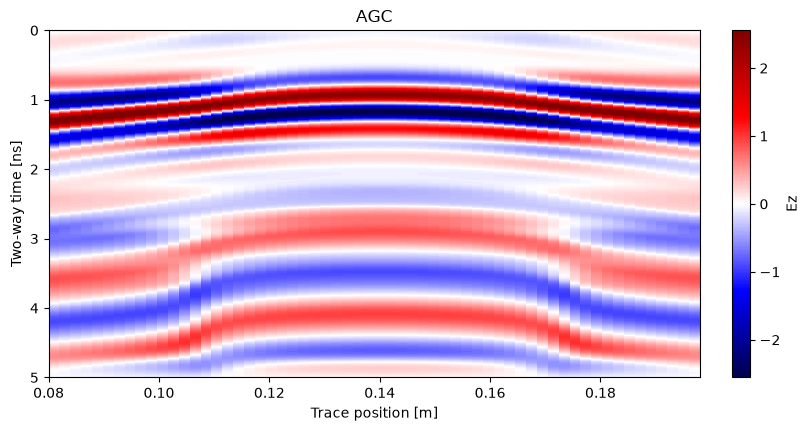

In [9]:
from scipy.ndimage import uniform_filter1d

# A silent sample would otherwise be divided by zero.
AGC_EPSILON = 1e-8


def gain_agc(data, dt, window_ns):
    """Divide by a running RMS so a weaker late reflection stays visible."""
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("dt must be a positive sample interval in seconds")
    if not np.isfinite(window_ns) or window_ns <= 0:
        raise ValueError("window_ns must be positive")
    values = _samples(data)
    window = max(int(round(window_ns * 1e-9 / float(dt))), 1)
    rms = np.sqrt(uniform_filter1d(values ** 2, size=window, axis=0, mode="nearest"))
    return _like(data, values / (rms + AGC_EPSILON))


gained = gain_agc(filtered, dt, AGC_WINDOW_NS)
show_scan(gained, "AGC")

## The sequence together

The same six stages, each with its own colour scale. Reading left to right: the raw record, the common time origin, the baseline removed, the horizontal direct wave removed, the antenna band kept, and the late arrivals brought up to the same level.

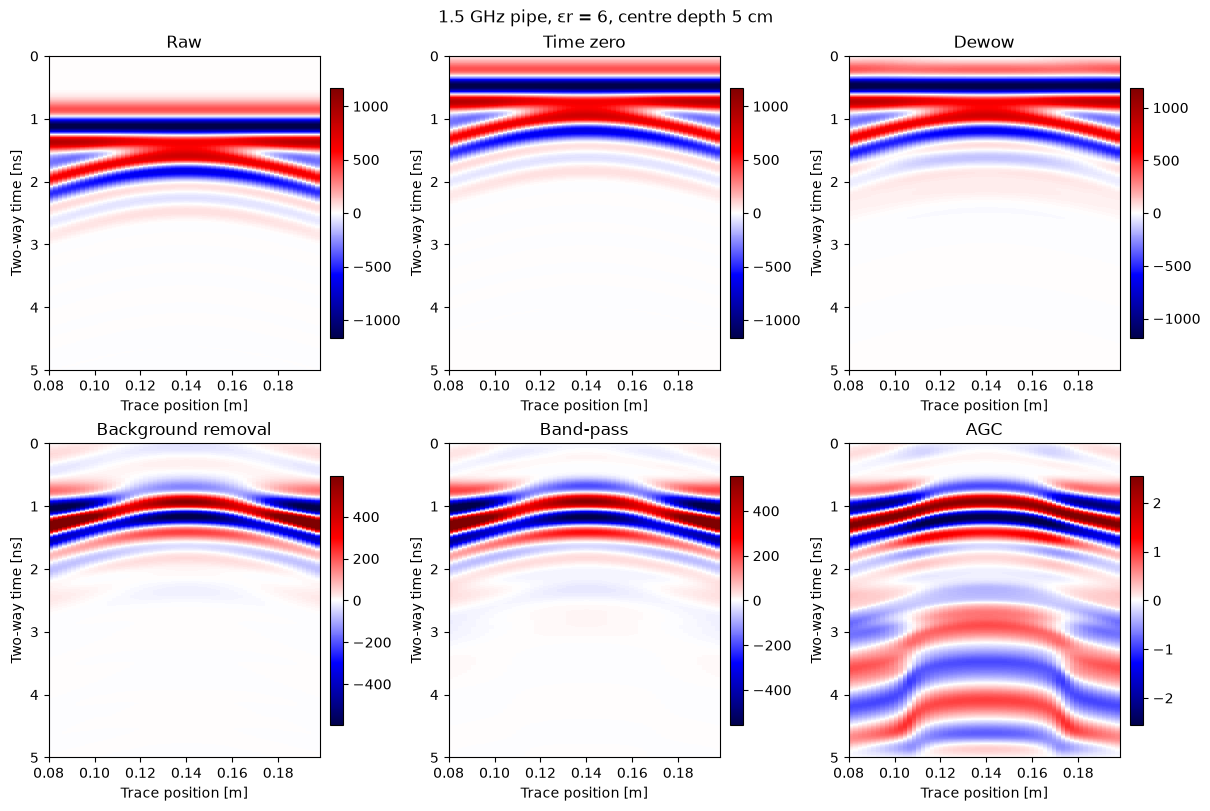

In [10]:
panels = (
    (raw, "Raw"),
    (zeroed, "Time zero"),
    (dewowed, "Dewow"),
    (cleaned, "Background removal"),
    (filtered, "Band-pass"),
    (gained, "AGC"),
)
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for ax, (data, title) in zip(axes.ravel(), panels):
    limit = float(np.percentile(np.abs(data), 99))
    if limit == 0:
        limit = 1.0
    image = ax.imshow(
        data,
        extent=extent,
        aspect="auto",
        cmap="seismic",
        vmin=-limit,
        vmax=limit,
        interpolation="nearest",
    )
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(title)
    ax.set_xlabel("Trace position [m]")
    ax.set_ylabel("Two-way time [ns]")
fig.suptitle("1.5 GHz pipe, εr = 6, centre depth 5 cm")
plt.show()